**OSS:** the problem with PCA is that we need to invert a matrix at some point in order to diagonalize the covariance matrix. Matrix invertion is computationally heavy, cause for a N x N matrix the cost for invertion goes as $N^3$

**OSS:** Try standardize the data first. StandardScaler from scikit

In [1]:
import urllib.request
import pandas as pd
urllib.request.urlretrieve("https://raw.githubusercontent.com/nshaud/ml_for_astro/main/stars.csv", "stars.csv")

('stars.csv', <http.client.HTTPMessage at 0x211effc5810>)

In [2]:
df_stars = pd.read_csv("stars.csv")

In [3]:
df_stars
df_val = df_stars.loc[:, 'Temperature (K)':'Absolute magnitude(Mv)']

In [4]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
# Assign unique integers from 0 to 6 to each star type
df_stars['Star type'] = le.fit_transform(df_stars['Star type'])
labels = le.inverse_transform(df_stars['Star type'])
class_names = le.classes_
print(class_names)

['Brown Dwarf' 'Hypergiant' 'Main Sequence' 'Red Dwarf' 'Supergiant'
 'White Dwarf']


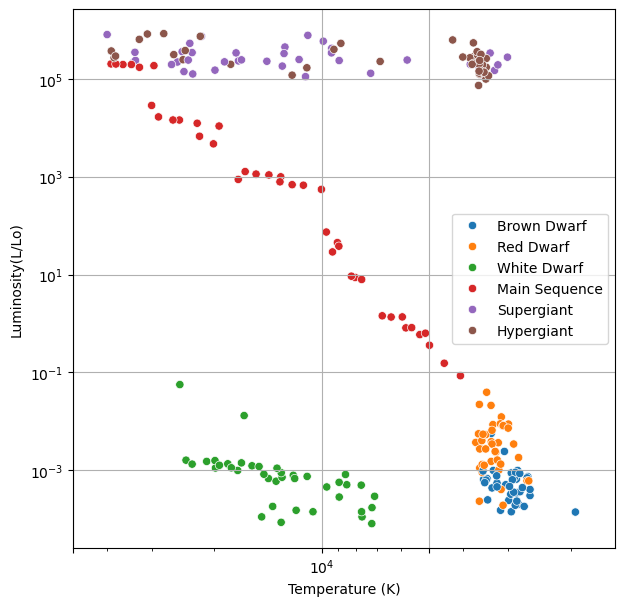

In [5]:
import seaborn as sns
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(7, 7))
sns.scatterplot(data=df_stars, x='Temperature (K)', y='Luminosity(L/Lo)', hue=labels)

plt.xscale('log')
plt.yscale('log')
plt.xticks([5000, 10000, 50000])
plt.xlim(5e4, 1.5e3)
plt.grid(True)
plt.show()

### Trying PCA

In [6]:
means = df_val.mean()
stds = df_val.std()

pca_data = (df_val-means)/stds

In [8]:
from sklearn.decomposition import PCA

# 1. Initialize and Fit
pca = PCA(n_components=4)
# transform() gives you the new coordinates (Principal Components)
pca_comp = pca.fit_transform(pca_data) 

# 2. Access the variance (Eigenvalues)
eigenvalues = pca.explained_variance_

# 3. Access the directions (Eigenvectors)
eigenvectors = pca.components_

print(eigenvalues.shape)
print(eigenvectors.shape)
print(pca_comp.shape)

(4,)
(4, 4)
(240, 4)


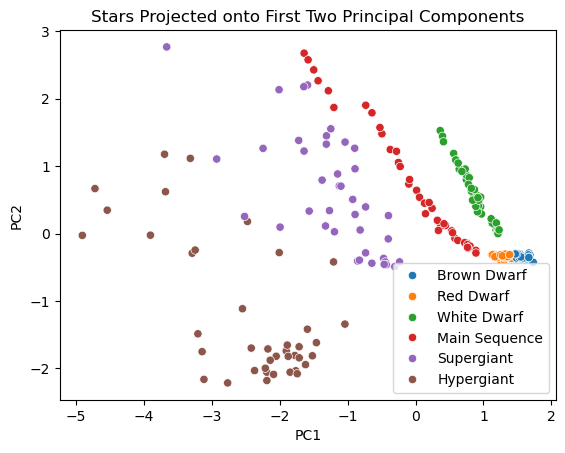

In [18]:
sns.scatterplot(x=pca_comp[:, 0], y=pca_comp[:, 1], hue=labels)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.title('Stars Projected onto First Two Principal Components')
plt.show()